# 1. Graph Plot

Hi Yuwei, please download "pip install --upgrade openap" before run this code

       lat      lon             x             y
0  41.6730 -82.9405  34294.835575 -59906.848214
1  41.7483 -82.7972  46142.632871 -51466.559845
2  42.4165 -82.6093  61083.159841  22950.677653
3  42.8532 -83.5498 -16010.594271  71261.019839
4  42.9150 -83.6020 -20245.675542  78143.975594
5  42.6869 -83.9603 -49605.978025  52927.698394
6  41.9662 -84.2975 -78054.676385 -26956.198092
7  41.7375 -84.1773 -68361.784026 -52488.584908


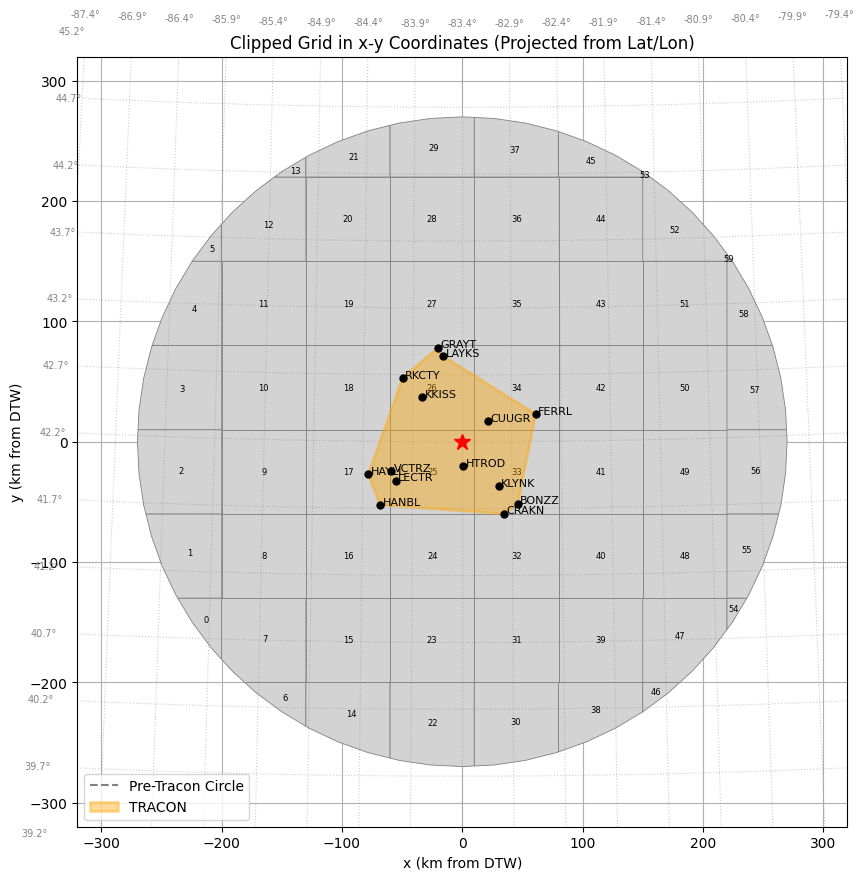

In [171]:
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, box, Point
from matplotlib.patches import Polygon as MplPolygon
import numpy as np

import openap
from openap import prop
import pandas as pd

# === Functions ==
def proj_with_defined_origin(lat, lon, lat0, lon0, inverse=False): #lon0, lat0 are the coordinates of the selected origin
    if not inverse: # from lat, lon to x, y
        bearings = openap.aero.bearing(lat0, lon0, lat, lon) / 180 * 3.14159
        distances = openap.aero.distance(lat0, lon0, lat, lon)
        x = distances * np.sin(bearings)
        y = distances * np.cos(bearings)

        return x, y

# === Constants ===
dtw_lat, dtw_lon = 42.2125, -83.3534
preTRACON_radius = 270 # unit: m
grid_step = 70000      # in meters (70 km)

# === STAR Fixes & TRACON Polygon ===
star_fixes = {
    "BONZZ": (41.7483, -82.7972), "CRAKN": (41.6730, -82.9405), "CUUGR": (42.3643, -83.0975),
    "FERRL": (42.4165, -82.6093), "GRAYT": (42.9150, -83.6020), "HANBL": (41.7375, -84.1773),
    "HAYLL": (41.9662, -84.2975), "HTROD": (42.0278, -83.3442), "KKISS": (42.5443, -83.7620),
    "KLYNK": (41.8793, -82.9888), "LAYKS": (42.8532, -83.5498), "LECTR": (41.9183, -84.0217),
    "RKCTY": (42.6869, -83.9603), "VCTRZ": (41.9878, -84.0670) # Kuang changed here to (lat, lon)
}
ordered_fix_names = ["CRAKN", "BONZZ", "FERRL", "LAYKS", "GRAYT", "RKCTY", "HAYLL", "HANBL"]
# tracon_polygon = Polygon([star_fixes[name] for name in ordered_fix_names])

# lat, lon of selected star fixes
selected_fix_coords = [star_fixes[name] for name in ordered_fix_names]
selected_fix_lat_list = [lat for lat, lon in selected_fix_coords]
selected_fix_lon_list = [lon for lat, lon in selected_fix_coords]

# lat, lon, x, y of selected star fixes with dtw at origin
selected_fix_x_list, selected_fix_y_list = proj_with_defined_origin(selected_fix_lat_list, selected_fix_lon_list, dtw_lat, dtw_lon)
selected_fix_df = pd.DataFrame({
    "lat": selected_fix_lat_list,
    "lon": selected_fix_lon_list,
    "x": selected_fix_x_list,
    "y": selected_fix_y_list
})
print(selected_fix_df)
tracon_polygon_xy = Polygon(zip(selected_fix_df.x, selected_fix_df.y))

# === Project All STAR Fixes ===
all_fix_lats = [lat for lat, lon in star_fixes.values()]
all_fix_lons = [lon for lat, lon in star_fixes.values()]
fix_x, fix_y = proj_with_defined_origin(all_fix_lats, all_fix_lons, dtw_lat, dtw_lon)

# === Pre-TRACON Circle Polygon ===
# Create a circle with 270 km radius around DTW (0, 0)
circle_polygon = Point(0, 0).buffer(preTRACON_radius * 1000)  # buffer radius in meters #filled circle
# preTRACON_circle_x, preTRACON_circle_y = circle_polygon.exterior.xy
circle_coords = (preTRACON_circle_x, preTRACON_circle_y)

# === Bounding box of circle ===
minx, miny, maxx, maxy = circle_polygon.bounds  # keep in meters

# === Valid grid cells (intersect circle but not fully in tracon) ===
grid_cells = []
clipped_cells = []

for x in np.arange(minx, maxx, grid_step):
    for y in np.arange(miny, maxy, grid_step):
        cell = box(x, y, x + grid_step, y + grid_step)
        if circle_polygon.intersects(cell) and not tracon_polygon_xy.contains(cell):
            clipped = cell.intersection(circle_polygon)
            if not clipped.is_empty:
                grid_cells.append(cell)
                clipped_cells.append(clipped)

# === Plot (km scale) ===
fig, ax = plt.subplots(figsize=(10, 10))

# Outer Circle (full dashed boundary)
circle_x, circle_y = circle_polygon.exterior.xy
circle_x_km = np.array(circle_x) / 1000
circle_y_km = np.array(circle_y) / 1000
ax.plot(circle_x, circle_y, linestyle='--', color='gray', linewidth=1.5, label='Pre-Tracon Circle', zorder=1)

# Clipped grid cells (gray boxes with labels)
for idx, poly in enumerate(clipped_cells):
    if isinstance(poly, Polygon):
        x, y = poly.exterior.xy
        x_km = np.array(x)/1000
        y_km = np.array(y)/1000
        ax.fill(x_km, y_km, facecolor='lightgray', edgecolor='gray', linewidth=0.6, zorder=2)
        cx, cy = poly.centroid.x, poly.centroid.y
        cx_km = cx / 1000
        cy_km = cy / 1000
        ax.text(cx_km, cy_km, str(idx), fontsize=6, ha='center', va='center', zorder=3)

# TRACON patch (on top)
tracon_coords_km = [(x / 1000, y / 1000) for x, y in tracon_polygon_xy.exterior.coords]
tracon_patch = MplPolygon(tracon_coords_km, closed=True,
                          edgecolor='orange', facecolor='orange', alpha=0.4,
                          linewidth=2, label='TRACON', zorder=5)
ax.add_patch(tracon_patch)

# tracon_x, tracon_y = tracon_polygon_xy.exterior.xy
# ax.fill(tracon_x, tracon_y, facecolor='orange', edgecolor='orange', alpha=0.4,
#         linewidth=2, label='TRACON', zorder=5)
# STAR fixes
for name, x0, y0 in zip(star_fixes.keys(), fix_x, fix_y):
    ax.plot(x0/1000, y0/1000, 'ko', markersize=5, zorder=6)
    ax.text((x0 + 2000)/1000, y0/1000, name, fontsize=8, zorder=6)

# KDTW
ax.plot(0, 0, 'r*', markersize=12, zorder=6)
# ax.text(2000, 0, 'KDTW', fontsize=11, fontweight='bold', zorder=6)

# Optional Lat/Lon Grid Overlay ===
lat_lon_grid = True  # Set to True to enable the grid
lat0, lon0 = dtw_lat, dtw_lon  # DTW as the projection origin

if lat_lon_grid:
    lat_lines = np.arange(lat0 - 3, lat0 + 3.5, 0.5)
    lon_lines = np.arange(lon0 - 4, lon0 + 4.5, 0.5)

    for lat in lat_lines:
        lons = np.linspace(lon_lines.min(), lon_lines.max(), 200)
        lats = np.full_like(lons, lat)
        x, y = proj_with_defined_origin(lats, lons, lat0, lon0)
        ax.plot(np.array(x) / 1000, np.array(y) / 1000, color='gray', linestyle=':', linewidth=0.8, alpha=0.4)
        ax.text(x[0] / 1000, y[0] / 1000, f"{lat:.1f}°", va="center", ha="right", fontsize=7, color="#848484")

    for lon in lon_lines:
        lats = np.linspace(lat_lines.min(), lat_lines.max(), 200)
        lons = np.full_like(lats, lon)
        x, y = proj_with_defined_origin(lats, lons, lat0, lon0)
        ax.plot(np.array(x) / 1000, np.array(y) / 1000, color='gray', linestyle=':', linewidth=0.8, alpha=0.4)
        ax.text(x[-1] / 1000, y[-1] / 1000 + 10, f"{lon:.1f}°", va="bottom", ha="center", fontsize=7, color="#848484")
        
# Layout
ax.set_title("Clipped Grid in x-y Coordinates (Projected from Lat/Lon)")
ax.set_aspect('equal')
minx_km, miny_km, maxx_km, maxy_km = [v / 1000 for v in (minx, miny, maxx, maxy)]
ax.set_xlim(minx_km - 50, maxx_km + 50)
ax.set_ylim(miny_km - 50, maxy_km + 50)
ax.set_xlabel("x (km from DTW)")
ax.set_ylabel("y (km from DTW)")
ax.legend()
ax.grid(True)
#plt.tight_layout()
plt.show()

# 2. Calculate the pre-TRACON entry and exit time / coordinate of the flight

In [173]:
import openap
from openap import prop

import numpy as np
import pandas as pd

from datetime import timedelta

from shapely.geometry import LineString, Point
from shapely.geometry.base import BaseGeometry

def proj_with_defined_origin(lat, lon, lat0, lon0, inverse=False): #lon0, lat0 are the coordinates of the selected origin
    if not inverse: # from lat, lon to x, y
        bearings = openap.aero.bearing(lat0, lon0, lat, lon) / 180 * 3.14159 #Lin/site-packages/openap/extra/aero
        distances = openap.aero.distance(lat0, lon0, lat, lon)
        x = distances * np.sin(bearings)
        y = distances * np.cos(bearings)

        return x, y
    
    else: # from x,  to lat, lon
        x, y = lon, lat
        distances = np.sqrt(x**2 + y**2)
        bearing = np.arctan2(x, y) * 180 / 3.14159
        lat, lon = openap.aero.latlon(lat0, lon0, distances, bearing)

        return lat, lon

def find_trajectory_intersection(df_traj, shape: BaseGeometry):
    """
    General function to find the first intersection between a trajectory and a Shapely shape.

    Parameters:
    - df_traj: Pandas DataFrame with 'x' and 'y' columns (in meters)
    - shape: A Shapely geometry object (e.g. Polygon or LineString)

    Returns:
    - intersection_point: tuple (x, y) if intersection found, else None
    - segment_index: index i such that the intersection occurs between points i and i+1
    """
    boundary = shape.boundary if hasattr(shape, "boundary") else shape  # handle Polygon or LineString

    for i in range(len(df_traj) - 1):
        p1 = (df_traj.iloc[i]["x"], df_traj.iloc[i]["y"])
        p2 = (df_traj.iloc[i + 1]["x"], df_traj.iloc[i + 1]["y"])
        segment = LineString([p1, p2])
        
        intersection = segment.intersection(boundary)

        if not intersection.is_empty:
            if intersection.geom_type == "Point":
                return (intersection.x, intersection.y), i
            elif intersection.geom_type == "MultiPoint":
                # Return the closest point to p1
                points = sorted(intersection.geoms, key=lambda pt: Point(p1).distance(pt))
                return (points[0].x, points[0].y), i

    return None, None

def interpolate_row_from_xy(df, x_target, y_target):
    """
    Interpolate a trajectory row given a coordinate (x, y).
    
    Parameters:
    - df: trajectory DataFrame with columns ['x', 'y', 'recTime', 'alt', 'groundSpeed', 'rateOfClimb', 'coord1', 'coord2']
    - x_target, y_target: coordinates in meters
    
    Returns:
    - interpolated_row: pd.Series representing the estimated state at (x, y)
    """
    point = Point(x_target, y_target)

    for i in range(len(df) - 1):
        row1 = df.iloc[i]
        row2 = df.iloc[i + 1]
        p1 = Point(row1["x"], row1["y"])
        p2 = Point(row2["x"], row2["y"])
        segment = LineString([p1, p2])

        if segment.distance(point) < 1e-6 and segment.length > 0:  # point is on segment
            dist_total = p1.distance(p2)
            dist_to_p1 = p1.distance(point)
            ratio = dist_to_p1 / dist_total

            interpolated = row1.copy()
            for col in ["alt", "groundSpeed", "rateOfClimb", "coord1", "coord2", "x", "y"]: #coord1 = lat,coord2 = lon
                interpolated[col] = row1[col] + ratio * (row2[col] - row1[col])

            # Interpolate time
            t1 = pd.to_datetime(row1["recTime"])
            t2 = pd.to_datetime(row2["recTime"])
            interpolated_time = t1 + (t2 - t1) * ratio
            interpolated["recTime"] = interpolated_time.round("s")

            # Keep acId and any other relevant metadata
            interpolated["acId"] = row1["acId"]
            return interpolated

    raise ValueError("Target point does not lie on any segment of the trajectory.")

In [191]:
# Fuel Estimation For A Single Flight
# Kuang Sun, May 2023

# input data processing package
import pandas as pd
from datetime import timedelta
import time

# input plotting functions
from shapely.geometry import Polygon, Point
import matplotlib.pyplot as plt

def main():
    start_time = time.time()  # Record start time

    ############
    # 1. Input #
    ############
    # 1.1 Aircraft No. and Type
    print("Please enter acId: (e.g. DAL1296_KDENtoKDTW)")
    # target_acId = input()  # For now this is manually inputted. However, it would be better if this info in incoporated into Eric's output file
    target_acId = "DAL1296_KDENtoKDTW"
    print("Please enter the aircraft type: (e.g. A321)")
    # target_acType = input() # For now this is manually inputted. However, it would be better if this info in incoporated into Yuwei's output file
    target_acType = "A321"

    # 1.2 DTW location
    dtw_coord = (42.2125, -83.3534)
    dtw_lat, dtw_lon = dtw_coord

    # 1.3 Arbitrary Size of pre-TRACON area
    print("Please enter radius of pre-TRACON area in km: (e.g. 270)")
    # preTRACON_radius = input() # For now this is manually inputted. However, it would be better if this info in incoporated into Eric's output file
    preTRACON_radius = 270
    
    # 1.4 Input Yuwei's csv and find the target flight (ref: https://openap.dev/fuel_emission.html) (coord1, coord2 = lat, lon)
    # i) first dataframe containing data for all the time for all the flights
    df_csv = pd.read_csv("D:/Folder/3. Files/U-M/Year 1/Semester 2/Summer LATTICE Lab Fast Project/FAST Fuel Estimation/data/filtered_rows.csv",
                     usecols=lambda col: col in [
                         "recTime", "acId", "groundSpeed", "alt", "rateOfClimb", "coord1", "coord2"],
                     dtype={"acId": str})  # Load the flight data into pandaframe df
    df_csv["recTime"] = pd.to_datetime(df_csv["recTime"], format='mixed')
    df_csv = df_csv.assign(d_ts=lambda d: d.recTime.diff().dt.total_seconds().bfill()) # recTime Setup in pandaframe df
    df_csv["alt"] = df_csv["alt"] * 100 # Altitude conversion pandaframe df
    df_by_acid = {acid: group for acid, group in df_csv.groupby('acId')} # Group by acId pandaframe df

    # ii) second dataframe containing data for all the time for the target flight
    df_target_hist = df_by_acid[target_acId]  # Select target aircraft from pandaframe df

    # iii) compute x, y coordinates of historic flight
    df_target_hist_x_column, df_target_hist_y_column = proj_with_defined_origin(df_target_hist["coord1"], df_target_hist["coord2"], dtw_lat, dtw_lon)
    df_target_hist['x'] = df_target_hist_x_column
    df_target_hist['y'] = df_target_hist_y_column

    # 1.6 Eric's Optimized Waypoints, which includes entering and exiting location for pre-TRACON
    print("Please enter Waypoints in (lat, lon) form (e.g. (-84.5078, 44.9031), (-84.5078, 44.8262)...)")
    #target_optWaypoints = input() # Eric need to convert output to tuple list format of [(float, float), (float, float), ...]
    target_optWaypoints = [
        (42.5298, -86.6081), (42.5192, -86.1996), (42.5192, -86.1227),
        (42.4423, -86.0458), (42.3654, -85.9689), (42.2885, -85.892),
        (42.2116, -85.8151), (42.1347, -85.7382), (42.0578, -85.6613),
        (41.9809, -85.5844), (41.9809, -85.5075), (41.9809, -85.4306),
        (41.9809, -85.3537), (41.9809, -85.2768), (41.9809, -85.1999),
        (41.9809, -85.123), (41.9809, -85.0461), (41.9809, -84.9692),
        (41.9809, -84.8923), (41.9809, -84.8154), (41.9809, -84.7385),
        (41.9809, -84.6616), (41.9809, -84.5847), (41.9809, -84.5078),
        (41.9809, -84.4309), (41.9809, -84.354), (41.9662, -84.2975)
    ] #the first one should be the entry point (intersection) and the last one should be a star fix

    print("=== Input Success === \n")

    ############################################
    # 2. Compute Pre-TRACON Entry & Exit Point #
    ############################################
    # 2.1 STAR Fixes
    # all STAR fixes
    star_fixes = {
        "BONZZ": (41.7483, -82.7972), "CRAKN": (41.6730, -82.9405), "CUUGR": (42.3643, -83.0975),
        "FERRL": (42.4165, -82.6093), "GRAYT": (42.9150, -83.6020), "HANBL": (41.7375, -84.1773),
        "HAYLL": (41.9662, -84.2975), "HTROD": (42.0278, -83.3442), "KKISS": (42.5443, -83.7620),
        "KLYNK": (41.8793, -82.9888), "LAYKS": (42.8532, -83.5498), "LECTR": (41.9183, -84.0217),
        "RKCTY": (42.6869, -83.9603), "VCTRZ": (41.9878, -84.0670) # (lat, lon)
    }
    
    # select a part of fixes to plot a simple TRACON region
    selected_fix_names = ["CRAKN", "BONZZ", "FERRL", "LAYKS", "GRAYT", "RKCTY", "HAYLL", "HANBL"] 
    selected_fix_coords = [star_fixes[name] for name in selected_fix_names]
    
    # lat, lon of selected star fixes
    selected_fix_lat_list = [lat for lat, lon in selected_fix_coords]
    selected_fix_lon_list = [lon for lat, lon in selected_fix_coords]
    
    # lat, lon, x, y of selected star fixes with dtw at origin
    selected_fix_x_list, selected_fix_y_list = proj_with_defined_origin(selected_fix_lat_list, selected_fix_lon_list, dtw_lat, dtw_lon)
    selected_fix_df = pd.DataFrame({
        "lat": selected_fix_lat_list,
        "lon": selected_fix_lon_list,
        "x": selected_fix_x_list,
        "y": selected_fix_y_list
    })
  
    # 2.2 TRACON Area
    # Create Shapely Polygon from TRACON boundary
    fix_points = list(zip(selected_fix_df["x"], selected_fix_df["y"]))
    TRACON_polygon = Polygon(fix_points) #filled polygon
    TRACON_polygon_x, TRACON_polygon_y = TRACON_polygon.exterior.xy

    # 2.3 Pre-TRACON Area
    # Create a circle with 300 km radius around DTW (0, 0)
    preTRACON_circle = Point(0, 0).buffer(preTRACON_radius*1000)  # buffer radius in meters #filled circle
    preTRACON_circle_x, preTRACON_circle_y = preTRACON_circle.exterior.xy

    # 2.4 Find Trajectory Intersection
    # Pre-TRACON circle & Trajectory Intersection
    preTRACON_entry, pre_idx = find_trajectory_intersection(df_target_hist, preTRACON_circle) # find intersection (entry point) x-y coordinate
    preTRACON_entry_lat, pre_entry_lon = proj_with_defined_origin(preTRACON_entry[0], preTRACON_entry[1], dtw_lat, dtw_lon) # translate intersection x-y coordinate to lat-lon coordinate
    interpolated_entry_row = interpolate_row_from_xy(df_target_hist, preTRACON_entry[0], preTRACON_entry[1]) # Interpolate entry time, altitude, groundspeed, rateOfClimb

    # TRACON polygon & Trajectory Intersection
    preTRACON_exit, tracon_idx = find_trajectory_intersection(df_target_hist, TRACON_polygon) # find intersection (exit point) x-y coordinate
    preTRACON_exit_lat, pre_exit_lon = proj_with_defined_origin(preTRACON_exit[0], preTRACON_exit[1], dtw_lat, dtw_lon) # translate intersection x-y coordinate to lat-lon coordinate
    interpolated_exit_row = interpolate_row_from_xy(df_target_hist, preTRACON_exit[0], preTRACON_exit[1]) # Interpolate entry time, altitude, groundspeed, rateOfClimb

    # 2.5 Find the segment of historic trajectory within pre-TRACON, and append the entry and exit rows
    df_target_preTRACON_hist = df_target_hist[
    (df_target_hist["recTime"] >= interpolated_entry_row["recTime"]) &
    (df_target_hist["recTime"] <= interpolated_exit_row["recTime"])] # include the rows within pre-TRACON time period
    
    df_target_preTRACON_hist = pd.concat(
        [pd.DataFrame([interpolated_entry_row]), df_target_preTRACON_hist,
         pd.DataFrame([interpolated_exit_row])]
    ).sort_values("recTime").reset_index(drop=True) # include the two rows entering and exiting the pre-TRACON
    print(df_target_preTRACON_hist) # the first row is entry rec_time, coord and other parameters, the last row is exit rec_time, coord and other parameters
    
    print("=== Compute Pre-TRACON Entry & Exit Point Success ===")

if __name__ == "__main__":
    main()

Please enter acId: (e.g. DAL1296_KDENtoKDTW)
Please enter the aircraft type: (e.g. A321)
Please enter radius of pre-TRACON area in km: (e.g. 270)
Please enter Waypoints in (lat, lon) form (e.g. (-84.5078, 44.9031), (-84.5078, 44.8262)...)
=== Input Success === 

               recTime                acId     coord1     coord2  \
0  2023-12-22 04:39:43  DAL1296_KDENtoKDTW  42.529814 -86.608113   
1  2023-12-22 04:39:44  DAL1296_KDENtoKDTW  42.529440 -86.604720   
2  2023-12-22 04:39:56  DAL1296_KDENtoKDTW  42.526390 -86.569170   
3  2023-12-22 04:40:08  DAL1296_KDENtoKDTW  42.523610 -86.533060   
4  2023-12-22 04:40:20  DAL1296_KDENtoKDTW  42.520830 -86.497500   
..                 ...                 ...        ...        ...   
71 2023-12-22 04:53:38  DAL1296_KDENtoKDTW  42.307220 -84.227780   
72 2023-12-22 04:53:50  DAL1296_KDENtoKDTW  42.304170 -84.198610   
73 2023-12-22 04:54:02  DAL1296_KDENtoKDTW  42.299440 -84.169720   
74 2023-12-22 04:54:08  DAL1296_KDENtoKDTW  42.295690 -84